In [34]:
import sympy as sp
import numpy as np
from scipy.optimize import minimize_scalar, minimize
import matplotlib.pyplot as plt
from IPython.display import display







# General eqaution
def general_continued_fraction_solver(a,b,N,loop=0):
    total = 0
    if loop < N:
        total = general_continued_fraction_solver(a,b,N,loop+1)
    if loop == 0:
       total= b(loop)+total
    else:
        total = total+b(loop)
        total = a(loop)/total
    return total




#  5 constants
# 
#brouncker's forumula
def brouncker_a(n):
    if n ==1:
        return 1
    else:
        return ((n-1)*2-1)**2
def brouncker_b(n):
    if n ==0:
        return 0
    elif n == 1:
        return 1
    else:
        return 2

#Euler's forumula
def Euler_a(n):
    return -n
def Euler_b(n):
    return n+3

#catalan's a forumula (1/2G)
def catalana_a(n):
    return -2*n**4
def catalana_b(n):
    return 3*n**2+3*n+1

#catalan's b forumula (2/2G-1)
def catalanb_a(n):
    return -2*n**3*(n+1)
def catalanb_b(n):
    return 3*n**2+3*n+1


#log2's forumula
def log2_b(n):
    n=n
    return 3*(n**2)+(7*n)+4
def log2_a(n):
    return (-2)*(n**2)*((n+1)**2)

#squroot2's forumula
def squroot2_a(n):

    return 1
def squroot2_b(n):
    if n==0 :
        return 1
    else:
        return 2






# 
# 5 functions
# 

# Values for x
varxpi = np.linspace(-2*np.pi,2*np.pi,400)
varxnorm= np.linspace(-10,10,400)
varxpos = np.linspace(1,40,400)
varxlog = np.linspace(-1,1,401)


# Tan(x)
def tanx_a(n):
    if n == 1:
     return varxpi
    else:
        return -varxpi**2
def tanx_b(n):
    if n==0 :
        return 0
    else:
        return ((n-1)*2+1)


# Ln(1+x)
def Ln1x_a(n):
    if n == 1:
     return varxlog
    else:
        return (n-1)**2*varxlog
def Ln1x_b(n):
    if n==0 :
        return 0
    else:
        return n-varxlog*(n-1)


# v varaiable for square root formula
vark = 1
# sqrt(x)
def sqrtx_a(n):
    # if n == 1:
    return varxpos - vark**2
def sqrtx_b(n):
    if n==0 :
        return vark
    else:
        return 2* vark

# arctan(x)
def arctan_a(n):
    if n==1 :
        return varxnorm
    else:
        return ((n-1)*varxnorm)**2

def arctan_b(n):
    if n==0 :
        return 0
    else:
        return ((n-1)*2)+1

# tanhx
def tanhx_a(n):
    return 1

def tanhx_b(n):
    if n==0 :
        return 0
    else:
        return (((n-1)*2)+1)/varxnorm



tablevars=[1,10,20,50,100,200,500,1000]




# notes below



# Testin


#
#  Table?
# 
# plot error as function with different n values
# error = |(estimated - acurrate)| / acurate
# 
# semilog y, or loglog
# make just plot error over my approach and true value
# 
# 10 , 50, 100, 200, 500, 1000, 1500
# 
# read me has 
# source, no ai statement
# 
#  report in overleaf
# 
#  use np.array for x
# 
# 
# Requirements:  
# table: axis, labels, legends ...  




#  current steps
# 
#
# @misc{InternationalUnionforConservationofNature.2017,
# editor = {{International Union for Conservation of Nature}},
# year = {2017},
# title = {Deforestation and Forest Degradation},
# url = {\url   {https://www.iucn.org/sites/dev/files/deforestation-    forest_degradation_issues_brief_final.pdf}},
# urldate = {07.07.2018},
# series = {Issues Brief}
# }
# 
# 
# 
# 
# 
#  create report
# 


results table
interations          pi/4                 e                    1/(1-ln(2))          square root of 2     brouncker's formula a brouncker's formula b
1                    1.0                  2.75                 3.428571428571429    1.5                  0.7142857142857143   0.4285714285714286  
10                   0.7604599047323506   2.7182818284759573   3.258920611594111    1.4142135516460548   0.5462001683108453   5.109152827774279   
20                   0.7729059516669596   2.718281828459045    3.2588913625322267   1.414213562373095    0.5458723663554843   2.4164005301187004  
50                   0.7803986631477525   2.718281828459045    3.258891353270929    1.4142135623730951   0.5458720318519534   2.4040449837160285  
100                  0.7828982258896381   2.718281828459045    3.258891353270929    1.4142135623730951   0.545872031851953    2.4040449835232196  
200                  0.7841481712097041   2.718281828459045    3.258891353270929    1.4142135623730951

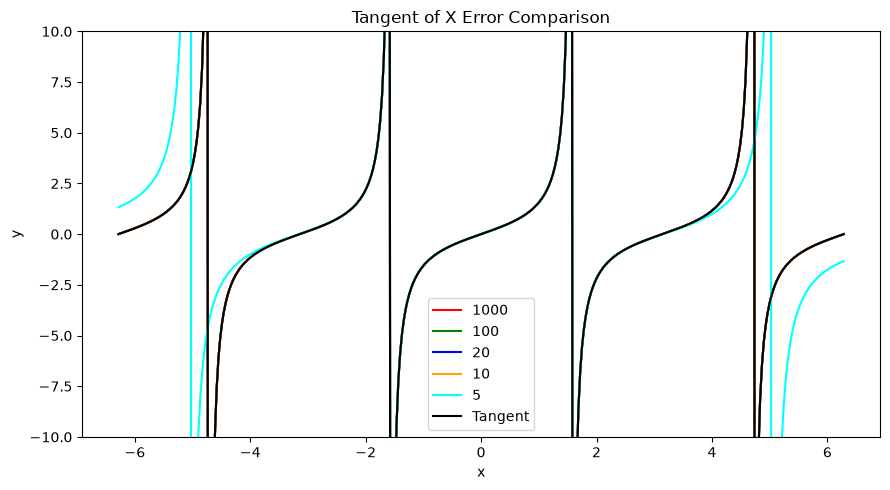

C:\Users\rayxc\AppData\Local\Temp\ipykernel_13264\1022185993.py:93: RuntimeWarning: divide by zero encountered in log
  ax.plot(varxlog, np.log(1+varxlog), "k-", label="Natural Log")


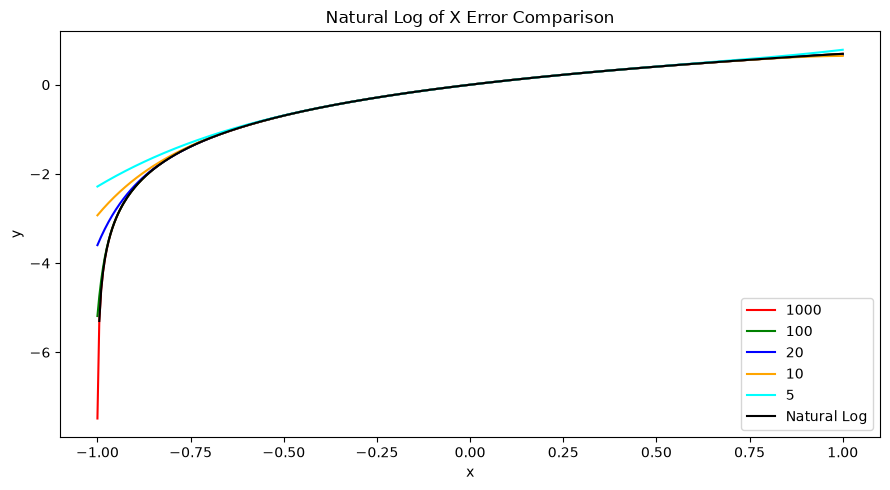

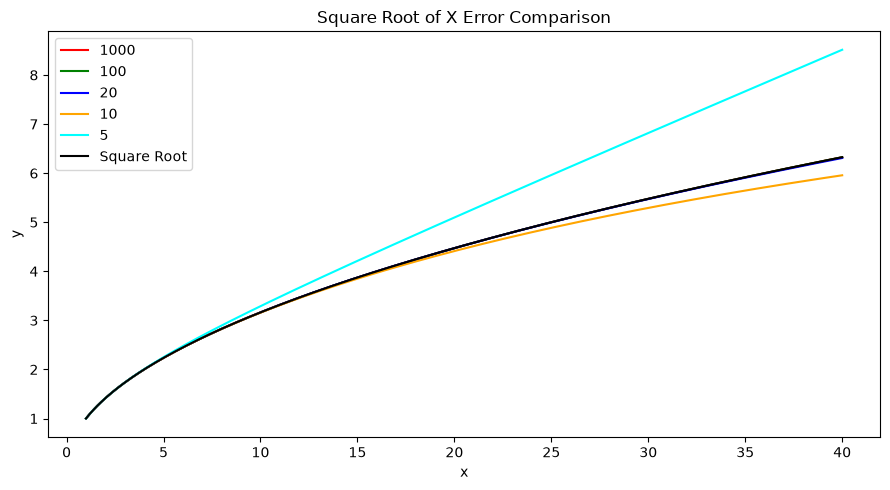

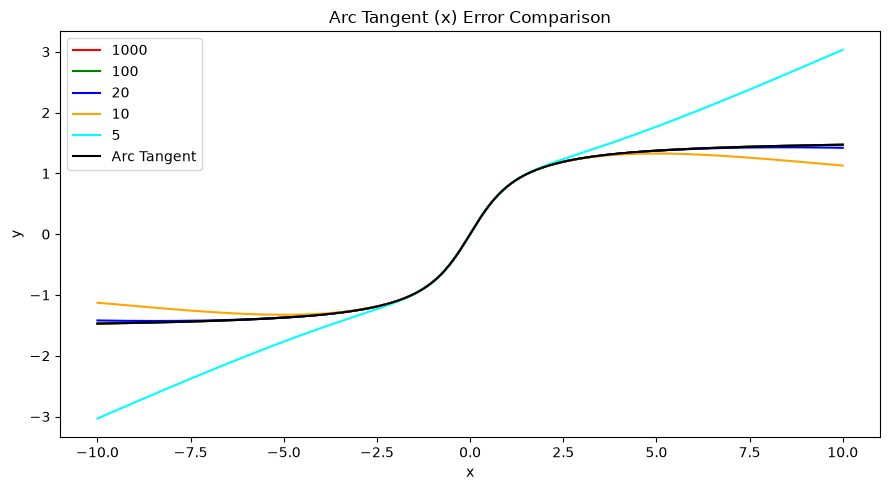

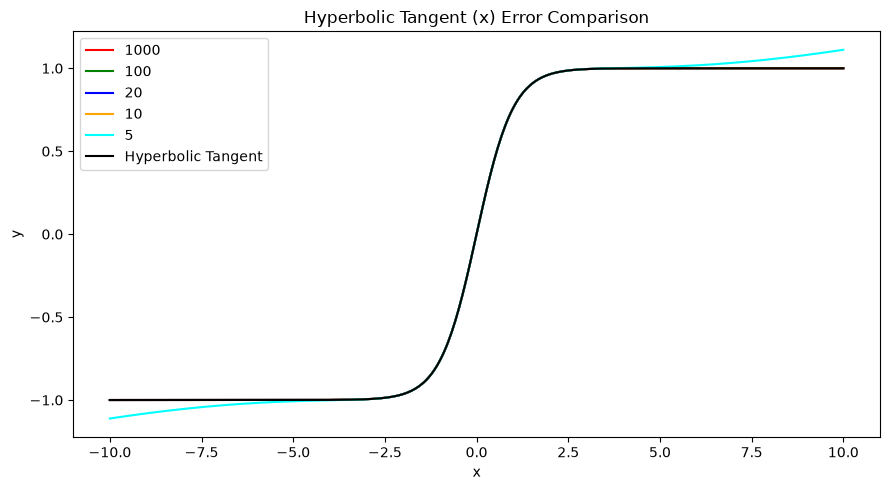

In [32]:


print("results table")
print(f"{'interations':<20}", f"{'pi/4':<20}",f"{'e':<20}",f"{'1/(1-ln(2))':<20}",f"{'square root of 2':<20}",f"{'brouncker\'s formula a':<20}",f"{'brouncker\'s formula b':<20}")
for i in tablevars:
    pi_rate =   general_continued_fraction_solver(brouncker_a,brouncker_b,i)
    Eul     =   general_continued_fraction_solver(Euler_a,Euler_b,i)
    loged   =   general_continued_fraction_solver(log2_a,log2_b,i)
    sqrt    =   general_continued_fraction_solver(squroot2_a,squroot2_b,i)
    catalantesta = general_continued_fraction_solver(catalana_a,catalana_b,i)
    catalantestb = general_continued_fraction_solver(catalanb_a,catalanb_b,i)

    print(f"{i:<20}", f"{pi_rate:<20}",f"{Eul:<20}",f"{loged:<20}",f"{sqrt:<20}",f"{catalantesta:<20}",f"{catalantestb:<20}")

catalantestrestult=0
print("\nfor the tables below we used brouncker\'s formula a as the forumula, and brouncker\'s formula b as the true value")
print("absolute error: |formula / command|")
print(f"{'interations':<25}", f"{'pi/4':<25}",f"{'e':<25}",f"{'1/(1-ln(2))':<25}",f"{'square root of 2':<25}",f"{'brouncker\'s formula':<25}")
for i in tablevars:
    pi_rate =   general_continued_fraction_solver(brouncker_a,brouncker_b,i)
    pi_rate = np.abs(pi_rate-(np.pi/4)) 

    Eul     =   general_continued_fraction_solver(Euler_a,Euler_b,i)
    Eul = np.abs(Eul-np.e)

    loged   =   general_continued_fraction_solver(log2_a,log2_b,i)
    loged = np.abs(loged-1/(1-np.log(2)))

    sqrt    =   general_continued_fraction_solver(squroot2_a,squroot2_b,i)
    sqrt    = np.abs(sqrt-np.sqrt(2))

    catalantesta = general_continued_fraction_solver(catalana_a,catalana_b,i)
    catalantestb = general_continued_fraction_solver(catalanb_a,catalanb_b,i)

    catalantestrestult = np.abs((2/((1/catalantesta)-1))-catalantestb)


    print(f"{i:<25}", f"{pi_rate:<25}",f"{Eul:<25}",f"{loged:<25}",f"{sqrt:<25}",f"{catalantestrestult:<25}")

print("\nrealative error: absolute error/ command")
for i in tablevars:
    pi_rate =   general_continued_fraction_solver(brouncker_a,brouncker_b,i)
    pi_rate = np.abs(pi_rate-(np.pi/4)) /(np.pi/4)

    Eul     =   general_continued_fraction_solver(Euler_a,Euler_b,i)
    Eul = np.abs(Eul-np.e)/np.e

    loged   =   general_continued_fraction_solver(log2_a,log2_b,i)
    loged = np.abs(loged-1/(1-np.log(2)))/(1-np.log(2))

    sqrt    =   general_continued_fraction_solver(squroot2_a,squroot2_b,i)
    sqrt    = np.abs(sqrt-np.sqrt(2))/np.sqrt(2)

    catalantesta = general_continued_fraction_solver(catalana_a,catalana_b,i)
    catalantestb = general_continued_fraction_solver(catalanb_a,catalanb_b,i)

    catalantestrestult = np.abs((2/((1/catalantesta)-1))-catalantestb)/catalantestb


    print(f"{i:<25}", f"{pi_rate:<25}",f"{Eul:<25}",f"{loged:<25}",f"{sqrt:<25}",f"{catalantestrestult:<25}")







fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(varxpi, general_continued_fraction_solver(tanx_a,tanx_b,1000), "-", label="1000", color="red")
ax.plot(varxpi, general_continued_fraction_solver(tanx_a,tanx_b,100), "-", label="100", color="green")
ax.plot(varxpi, general_continued_fraction_solver(tanx_a,tanx_b,20), "-", label="20", color="blue")
ax.plot(varxpi, general_continued_fraction_solver(tanx_a,tanx_b,10), "-", label="10", color="orange")
ax.plot(varxpi, general_continued_fraction_solver(tanx_a,tanx_b,5), "-", label="5", color="cyan")
ax.plot(varxpi, np.tan(varxpi), "k-", label="Tangent")
ax.set_ylim(-10,10)
ax.set_title("Tangent of X Error Comparison")
ax.set_xlabel("x")
ax.set_ylabel("y")

ax.legend()
fig.tight_layout()
fig.savefig("tanx.pdf")

plt.show()


# issue dividing by zero?
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(varxlog, general_continued_fraction_solver(Ln1x_a,Ln1x_b,1000), "-", label="1000", color="red")
ax.plot(varxlog, general_continued_fraction_solver(Ln1x_a,Ln1x_b,100), "-", label="100", color="green")
ax.plot(varxlog, general_continued_fraction_solver(Ln1x_a,Ln1x_b,20), "-", label="20", color="blue")
ax.plot(varxlog, general_continued_fraction_solver(Ln1x_a,Ln1x_b,10), "-", label="10", color="orange")
ax.plot(varxlog, general_continued_fraction_solver(Ln1x_a,Ln1x_b,5), "-", label="5", color="cyan")

ax.plot(varxlog, np.log(1+varxlog), "k-", label="Natural Log")
ax.set_title("Natural Log of X Error Comparison")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.legend()
fig.tight_layout()
fig.savefig("lnx.pdf")
plt.show()


fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(varxpos, general_continued_fraction_solver(sqrtx_a,sqrtx_b,1000), "-", label="1000", color="red")
ax.plot(varxpos, general_continued_fraction_solver(sqrtx_a,sqrtx_b,100), "-", label="100", color="green")
ax.plot(varxpos, general_continued_fraction_solver(sqrtx_a,sqrtx_b,20), "-", label="20", color="blue")
ax.plot(varxpos, general_continued_fraction_solver(sqrtx_a,sqrtx_b,10), "-", label="10", color="orange")
ax.plot(varxpos, general_continued_fraction_solver(sqrtx_a,sqrtx_b,5), "-", label="5", color="cyan")
ax.plot(varxpos, np.sqrt(varxpos), "k-", label="Square Root")
ax.set_title("Square Root of X Error Comparison")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.legend()
fig.tight_layout()
fig.savefig("squareroot.pdf")
plt.show()


fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(varxnorm, general_continued_fraction_solver(arctan_a,arctan_b,1000), "-", label="1000", color="red")
ax.plot(varxnorm, general_continued_fraction_solver(arctan_a,arctan_b,100), "-", label="100", color="green")
ax.plot(varxnorm, general_continued_fraction_solver(arctan_a,arctan_b,20), "-", label="20", color="blue")
ax.plot(varxnorm, general_continued_fraction_solver(arctan_a,arctan_b,10), "-", label="10", color="orange")
ax.plot(varxnorm, general_continued_fraction_solver(arctan_a,arctan_b,5), "-", label="5", color="cyan")
ax.plot(varxnorm, np.arctan(varxnorm), "k-", label="Arc Tangent")
ax.set_title("Arc Tangent (x) Error Comparison")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.legend()
fig.tight_layout()
fig.savefig("arctan.pdf")
plt.show()


fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(varxnorm, general_continued_fraction_solver(tanhx_a,tanhx_b,1000), "-", label="1000", color="red")
ax.plot(varxnorm, general_continued_fraction_solver(tanhx_a,tanhx_b,100), "-", label="100", color="green")
ax.plot(varxnorm, general_continued_fraction_solver(tanhx_a,tanhx_b,20), "-", label="20", color="blue")
ax.plot(varxnorm, general_continued_fraction_solver(tanhx_a,tanhx_b,10), "-", label="10", color="orange")
ax.plot(varxnorm, general_continued_fraction_solver(tanhx_a,tanhx_b,5), "-", label="5", color="cyan")
ax.plot(varxnorm, np.tanh(varxnorm), "k-", label="Hyperbolic Tangent")
ax.set_title("Hyperbolic Tangent (x) Error Comparison")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.legend()
fig.tight_layout()
fig.savefig("tanhx.pdf")
plt.show()
